In [5]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
from scipy.stats import multivariate_normal
import os
import sys

import matplotlib

import plotly.graph_objects as go

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

max_angle = 1000000 * np.pi / 180

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']

In [6]:
def plot_cov_ellipse(mean, cov, color='b'):
    phi = np.linspace(0, 2*np.pi, 100)
    chol = np.linalg.cholesky(cov[:2, :2])
    ellipse = np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color)
    ellipse = 2*np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color, ls='--')

  0%|          | 0/10 [00:00<?, ?it/s]

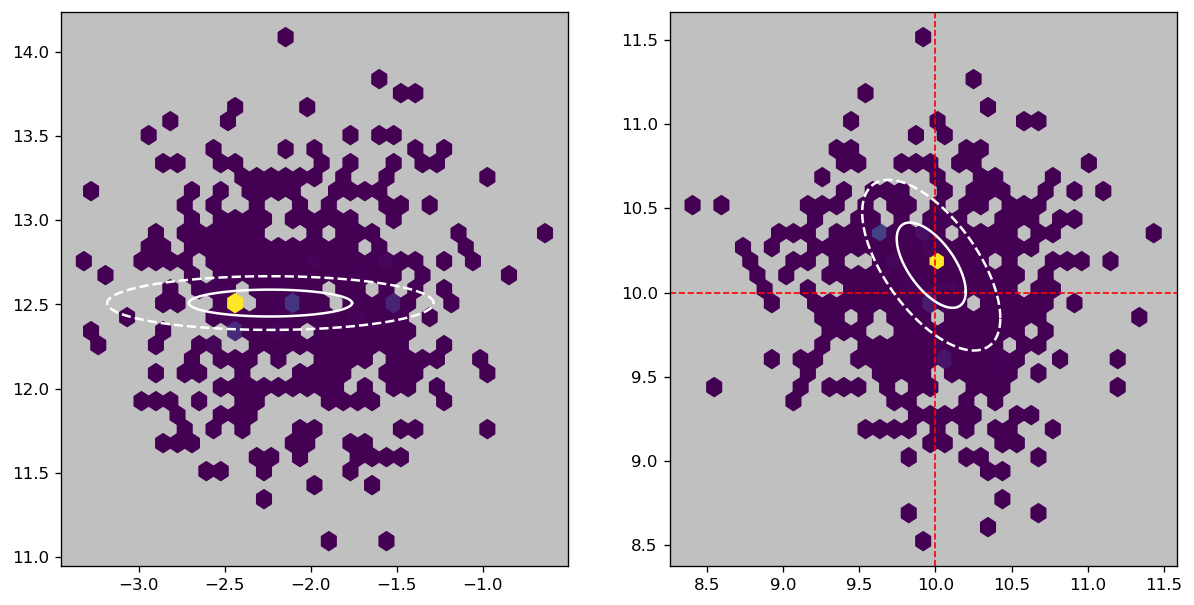

 10%|█         | 1/10 [05:30<49:31, 330.21s/it]

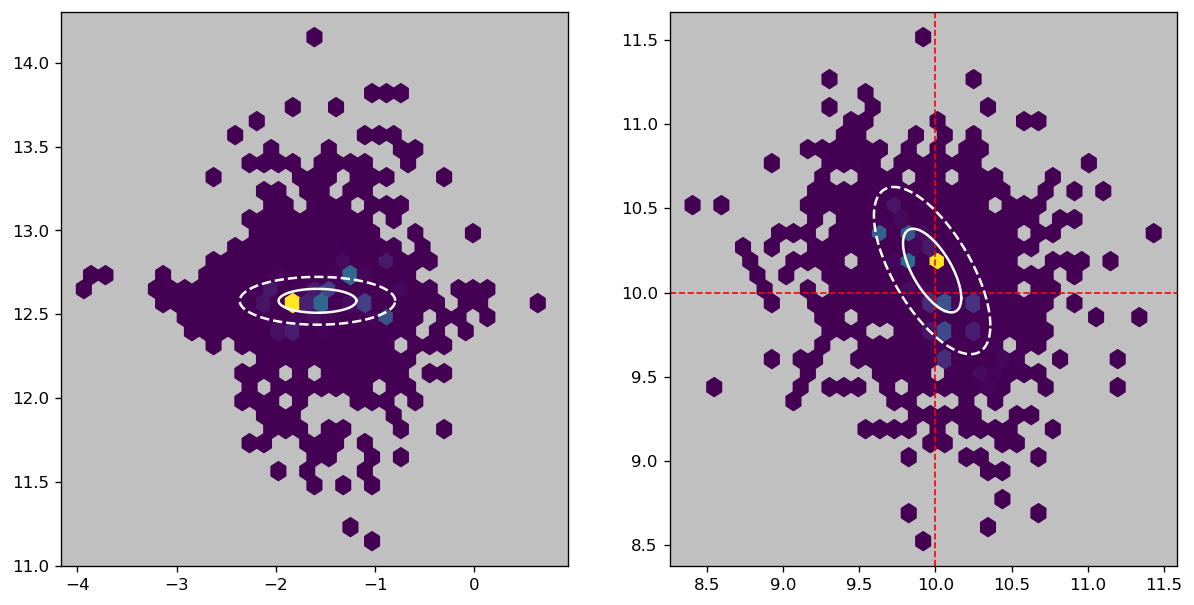

 20%|██        | 2/10 [10:54<43:33, 326.66s/it]

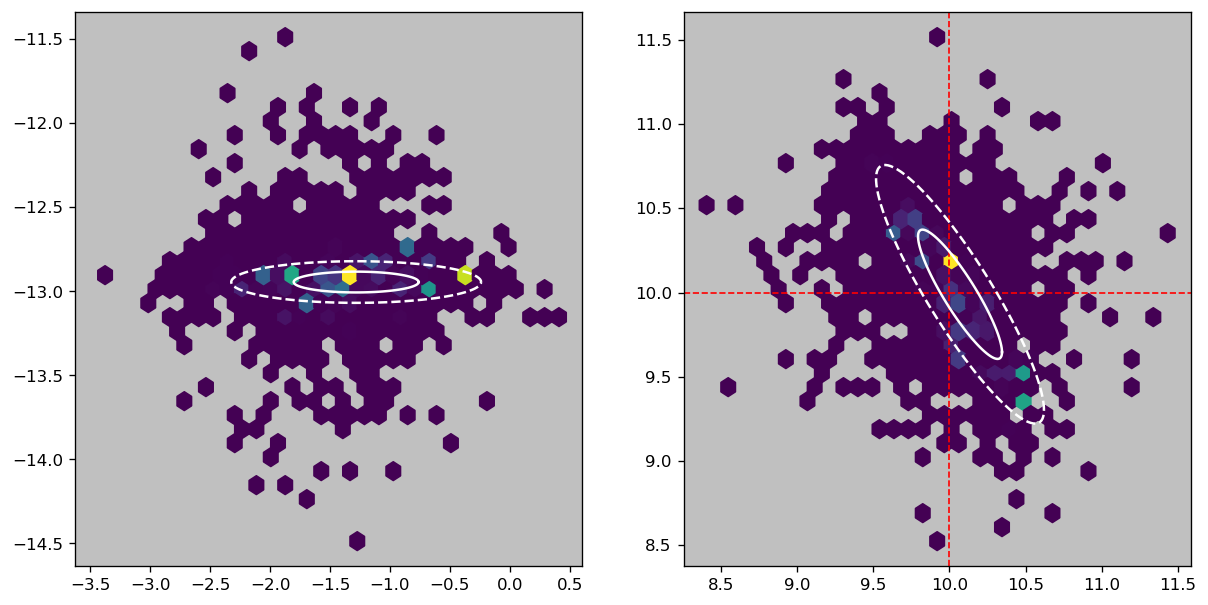

 30%|███       | 3/10 [15:27<35:16, 302.39s/it]

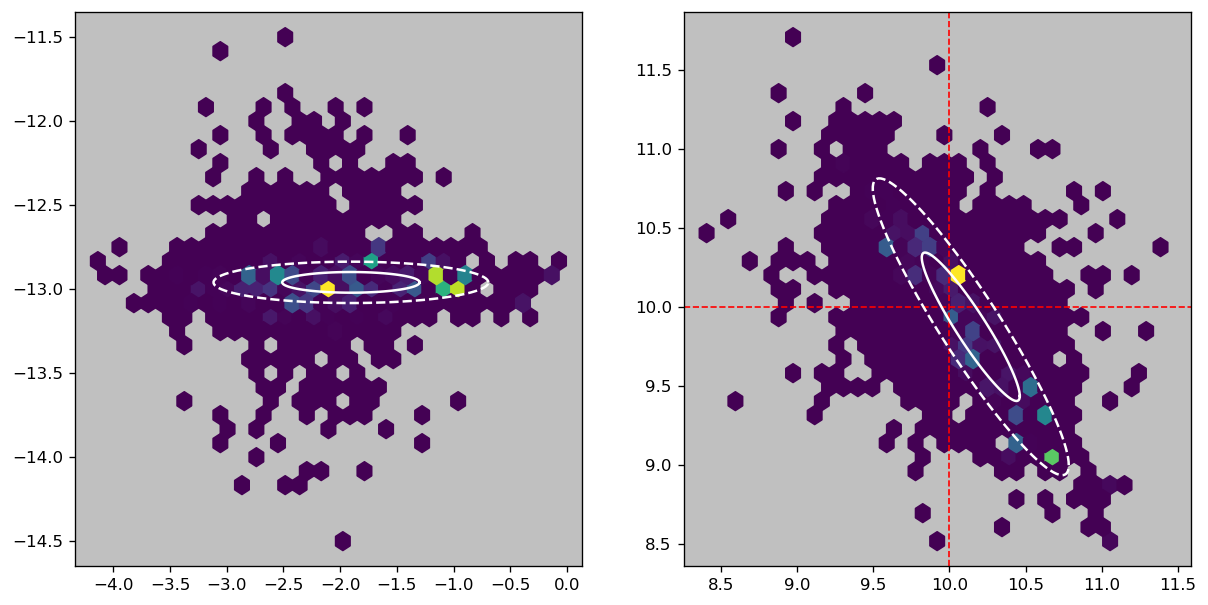

 40%|████      | 4/10 [18:37<25:47, 257.87s/it]

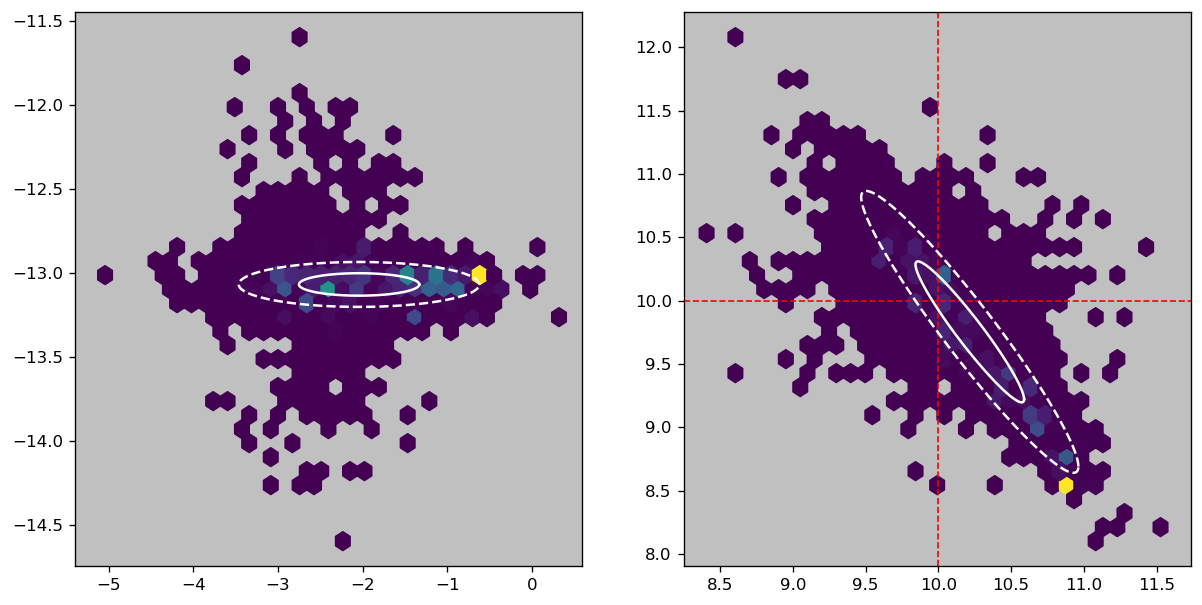

 50%|█████     | 5/10 [22:07<20:03, 240.72s/it]

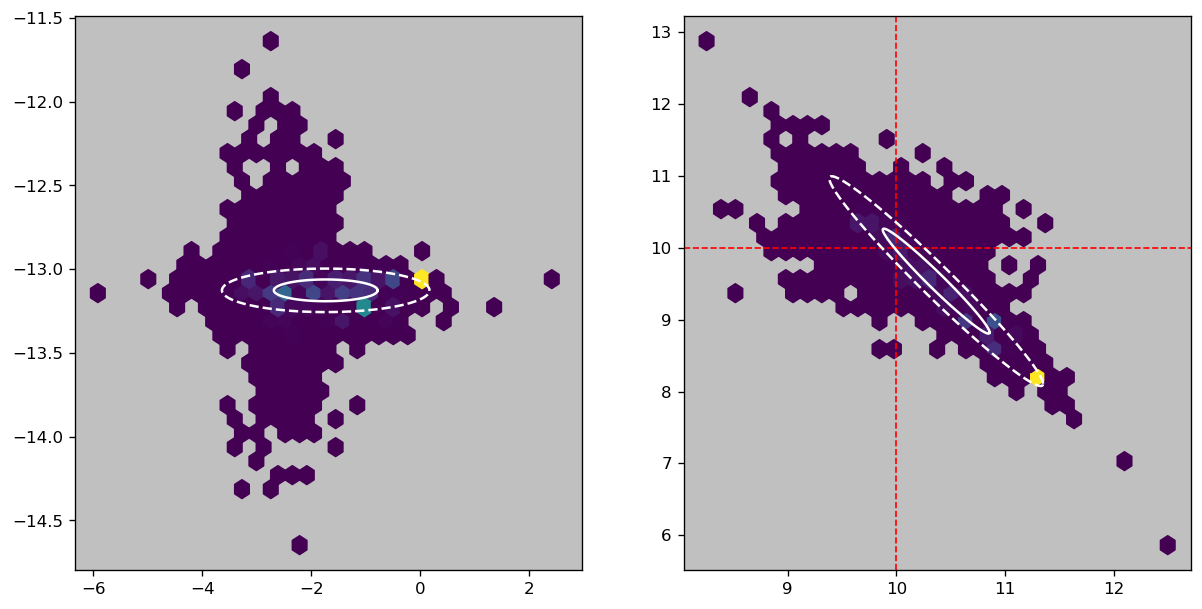

 60%|██████    | 6/10 [25:29<15:09, 227.43s/it]

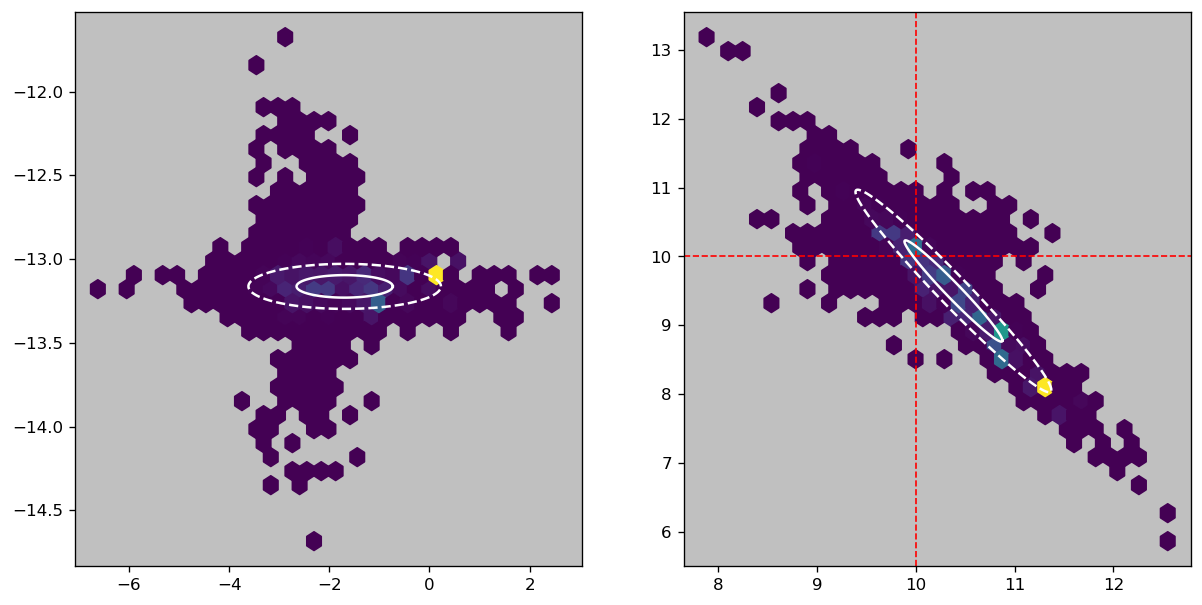

 70%|███████   | 7/10 [28:52<10:58, 219.34s/it]

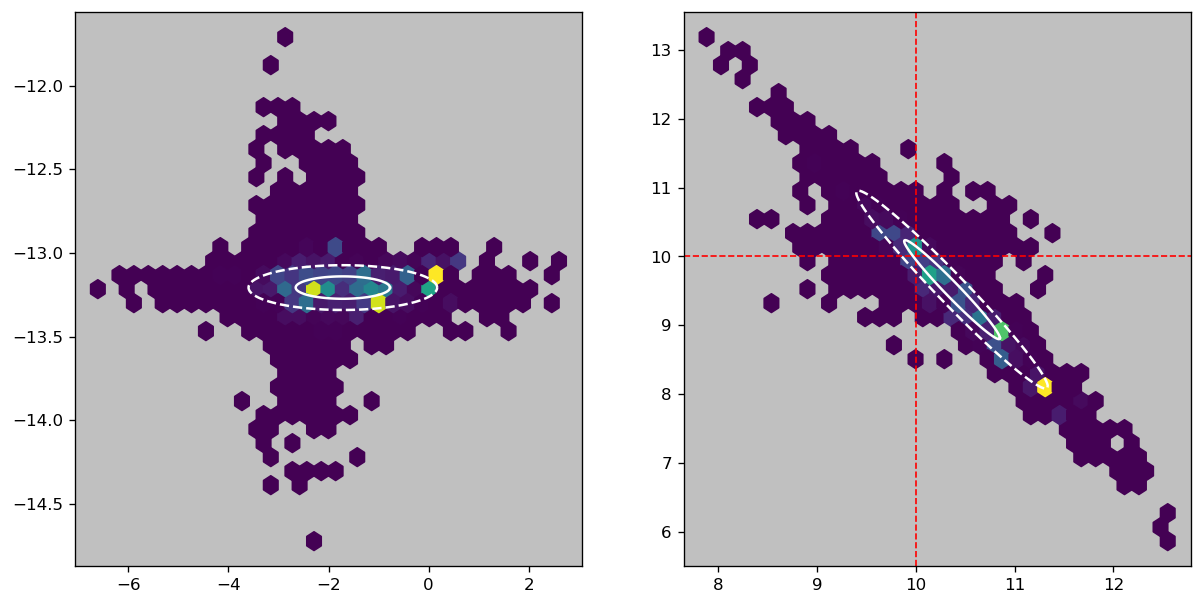

 80%|████████  | 8/10 [32:13<07:07, 213.57s/it]

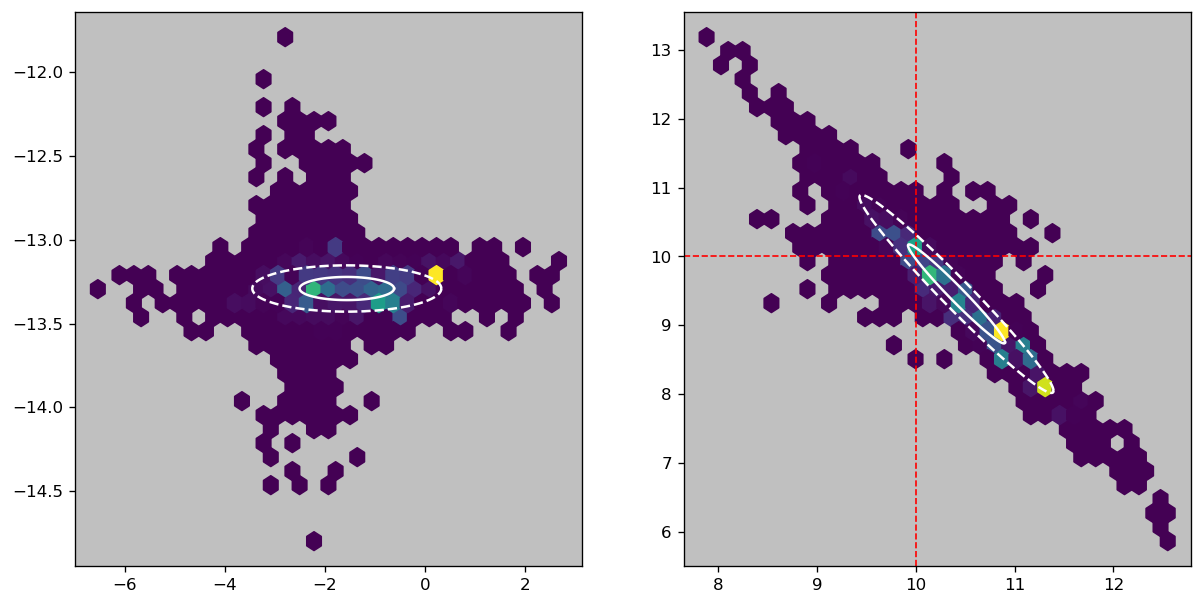

 90%|█████████ | 9/10 [35:31<03:28, 208.88s/it]

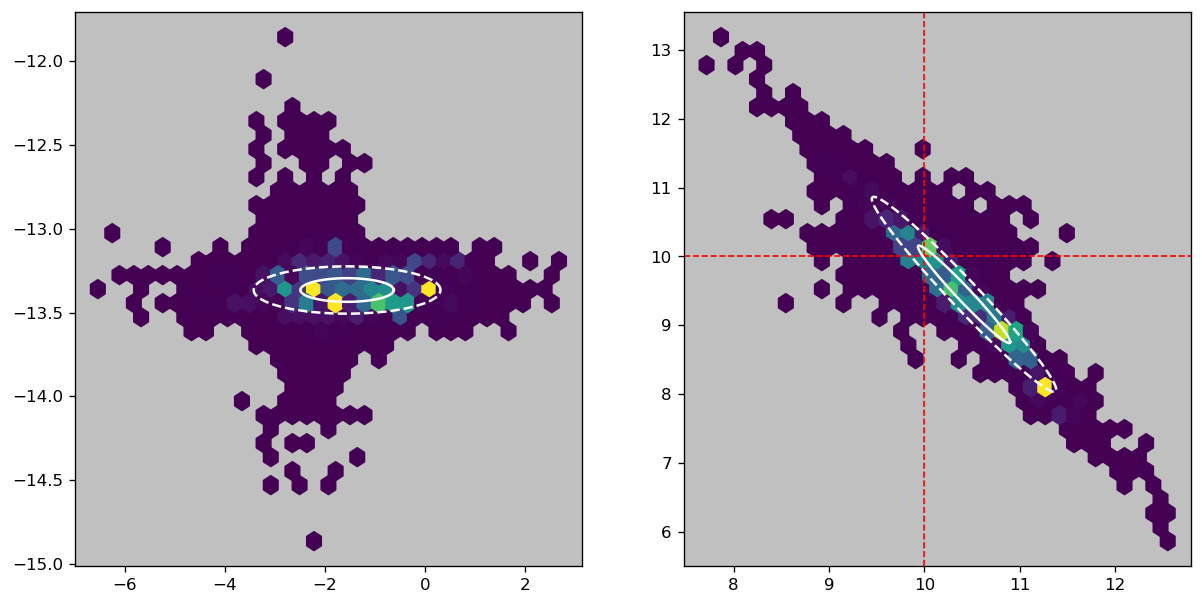

100%|██████████| 10/10 [38:56<00:00, 233.63s/it]


In [7]:
search_size = 2
initial_radius = 0.1

ndims = 3

sample_count = 512
d0 = 0
d1 = 1
centers = np.pad(ALPHAS, (0, ndims-ALPHAS.shape[0]), 'constant', constant_values=0.)
mean = centers
cov = np.eye(ndims) * initial_radius
COVS = [cov]
ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

progression = range(10)

for prog in tqdm(progression):
    distribution = multivariate_normal(mean=mean, cov=search_size*cov)
    coords = distribution.rvs(sample_count)
    likelihood = distribution.pdf(coords)
    logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   coords, torque_limit=max_angle,
                                   n_particles=400
                                   )
    logl = logl - np.max(logl)
    target_density = np.exp(logl)
    target_density = target_density / np.sum(target_density)

    ALL_COORDS = np.concatenate((ALL_COORDS, coords))
    ALL_TARGET_DENSITIES = np.concatenate((ALL_TARGET_DENSITIES, target_density))
    ALL_LIKELIHOODS = np.concatenate((ALL_LIKELIHOODS, likelihood))

    mean = np.average(ALL_COORDS, axis=0, weights=ALL_TARGET_DENSITIES/ALL_LIKELIHOODS)
    cov = np.cov(ALL_COORDS.T, aweights=ALL_TARGET_DENSITIES/ALL_LIKELIHOODS)

    eivals, eivecs = np.linalg.eig(cov)

    def rotate(vec):
        return np.dot(vec, eivecs)
    
    def rotate_mat(mat):
        return np.dot(np.dot(eivecs.T, mat), eivecs)

    COVS.append(cov)

    test_coords = np.random.multivariate_normal(mean, search_size*cov, 128)
    test_coords_rotated = np.dot(test_coords, eivecs)

    plt.figure(dpi=120, figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.gca().set_facecolor('silver')
    chan = np.exp(ALL_TARGET_DENSITIES/10)
    plt.hexbin(rotate(ALL_COORDS)[:, d0], rotate(ALL_COORDS)[:, d1], C=chan, gridsize=32)
    plot_cov_ellipse(rotate(mean), rotate_mat(cov), color='w')
    plt.subplot(1, 2, 2)
    plt.gca().set_facecolor('silver')
    chan = np.exp(ALL_TARGET_DENSITIES/10)
    plt.hexbin((ALL_COORDS)[:, d0], (ALL_COORDS)[:, d1], C=chan, gridsize=32)
    plt.axvline((ALPHAS)[0], color='r', linestyle='--', lw=1)
    plt.axhline((ALPHAS)[1], color='r', linestyle='--', lw=1)
    plot_cov_ellipse(mean, cov, color='w')
    plt.savefig(f"img/proposal_convergence{prog}.png", dpi=300)
    plt.show()

Text(0, 0.5, 'Covariance matrix element')

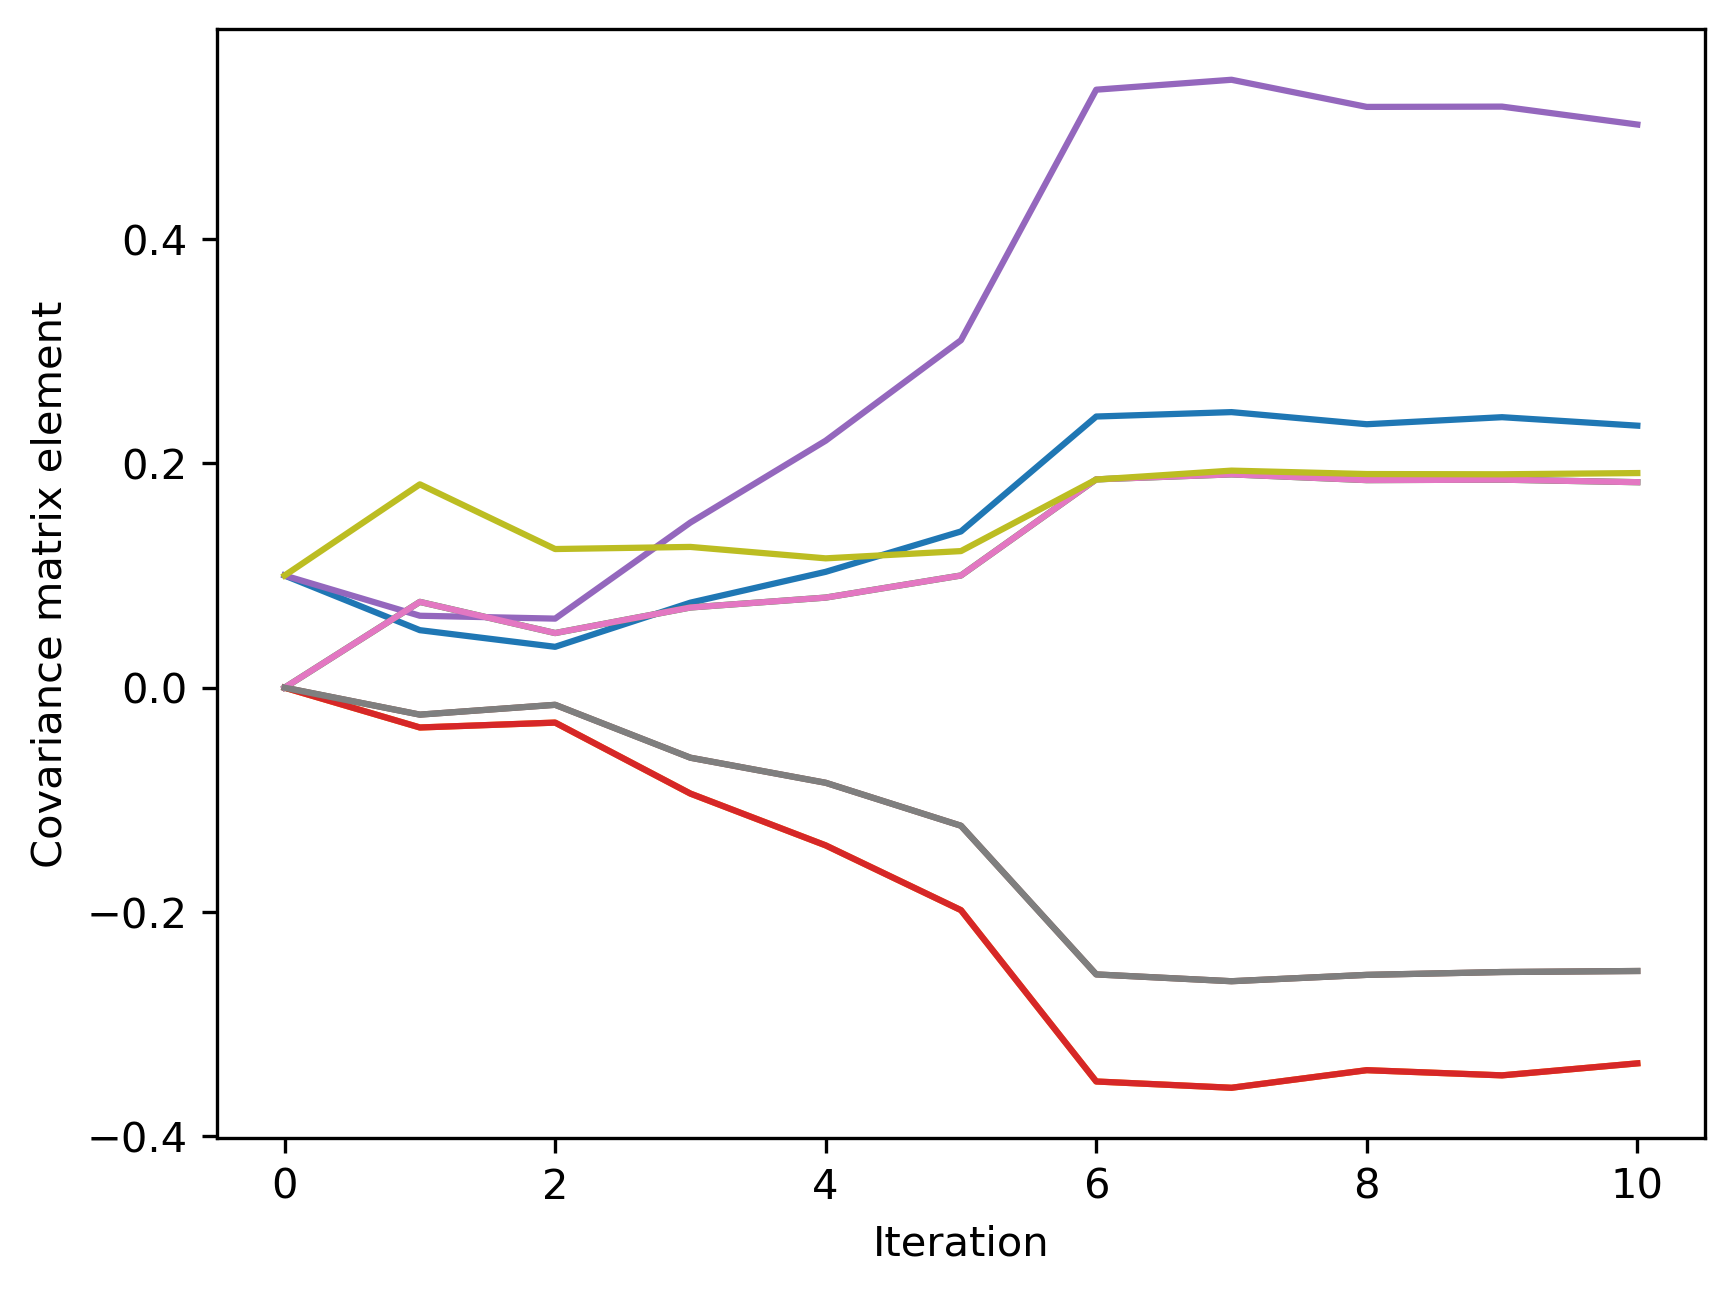

In [10]:
plt.figure(dpi=300)
COVS_flat = [cov.flatten() for cov in COVS]
COVS_flat = np.stack(COVS_flat, axis=0)
plt.plot(COVS_flat)
plt.xlabel("Iteration")
plt.ylabel("Covariance matrix element")

In [11]:
np.savez("proposal_distribution.npz", mean=mean, cov=cov)